# 8-1. 가설검정 기초 (주석 버전)

이 노트북에서 다루는 내용
1. 데이터 불러오기와 기본 탐색
2. 검정 결과를 일관되게 출력하는 `verdict()` 함수
3. 시뮬레이션으로 보는 **1종 오류(α)**, **2종 오류(β)**, **검정력(1-β)**
4. 정규성 확인: 히스토그램 · Q-Q plot · Shapiro-Wilk 검정

## 0. 라이브러리 불러오기

In [1]:
# 경고 메시지가 출력을 어지럽히지 않도록 숨김
import warnings
warnings.filterwarnings('ignore')

import numpy as np                 # 수치 계산, 난수 생성
import pandas as pd                # 표 형태 데이터(DataFrame) 처리
import matplotlib.pyplot as plt    # 시각화

from scipy import stats            # t검정, 정규성 검정 등 통계 함수
import statsmodels.api as sm
from statsmodels.formula.api import ols, logit                                  # 회귀분석(선형/로지스틱)
from statsmodels.stats.proportion import proportions_ztest, proportion_confint  # 비율 검정, 비율 신뢰구간
from statsmodels.stats.multicomp import pairwise_tukeyhsd                       # ANOVA 사후검정(Tukey HSD)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, r2_score, mean_squared_error, classification_report)

# 그래프에서 한글이 깨지지 않도록 윈도우 기본 한글 폰트 지정
plt.rcParams['font.family'] = 'Malgun Gothic'

## 1. 데이터 불러오기와 기본 탐색

In [2]:
df = pd.read_csv('./test.csv')
print(df.shape)        # (행 수, 열 수)

# 첫 번째 열(저장할 때 같이 들어간 인덱스 열)을 제외하고 나머지 열만 사용
df = df.iloc[:, 1:]
print(df.shape)        # 열이 하나 줄었는지 확인
df.head()              # 앞 5행 미리보기

(300, 11)
(300, 10)


,line,work_shift,supplier,oven_temp,humidity,speed,thickness,defect,rework_min,thickness_dev
0,A,주간,Y,232.4,50.5,1.23,108.5,0,14.2,1.5
1,A,야간,Y,229.3,54.4,1.12,115.2,0,10.9,5.2
2,A,야간,X,220.8,48.5,1.27,106.2,0,33.8,3.8
3,A,주간,X,234.6,52.2,1.12,117.4,0,31.2,7.4
4,A,주간,X,227.0,51.3,1.20,118.7,0,7.2,8.7


In [3]:
# 열별 데이터 타입, 결측치가 아닌 값의 개수, 메모리 사용량 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   line           300 non-null    object 
 1   work_shift     300 non-null    object 
 2   supplier       300 non-null    object 
 3   oven_temp      300 non-null    float64
 4   humidity       300 non-null    float64
 5   speed          300 non-null    float64
 6   thickness      300 non-null    float64
 7   defect         300 non-null    int64  
 8   rework_min     300 non-null    float64
 9   thickness_dev  300 non-null    float64
dtypes: float64(6), int64(1), object(3)
memory usage: 23.6+ KB


In [4]:
# 수치형 열의 요약통계량(개수, 평균, 표준편차, 최소/사분위/최대)
# .T 로 전치해서 열 이름이 행으로 오게 하면 보기 편함
df.describe().T

,count,mean,std,min,25%,50%,75%,max
oven_temp,300.0,229.559333,5.091650,215.20,225.9750,229.40,232.800,243.00
humidity,300.0,50.042333,7.967516,20.80,45.4000,50.35,55.025,75.40
speed,300.0,1.194967,0.152928,0.78,1.0975,1.20,1.300,1.62
thickness,300.0,106.435000,9.613776,83.20,99.7750,106.60,112.925,131.30
defect,300.0,0.136667,0.344069,0.00,0.0000,0.00,0.000,1.00
rework_min,300.0,28.733333,21.953154,4.60,16.4000,23.40,34.025,173.70
thickness_dev,300.0,8.214333,6.121722,0.10,3.2750,6.90,12.600,26.80


## 2. 검정 결과 출력 함수 `verdict()`

- **유의수준 α(ALPHA)**: 귀무가설(H0)이 참인데 기각해 버릴 위험을 어디까지 허용할지 정한 기준 (보통 0.05)
- 판정 규칙: **p-value < α 이면 H0 기각**, 아니면 기각하지 못함
- "기각 못함"은 "H0가 참이다"라는 뜻이 아니라 **차이가 있다고 말할 근거가 부족하다**는 뜻

In [5]:
ALPHA = 0.05   # 유의수준
LOG = []       # 여러 검정 결과를 모아두는 리스트 (나중에 표로 정리할 때 사용)

def verdict(name, p, h0='', reject_msg = '', keep_msg = '', stat = None, alpha = ALPHA) :
    """
    name       : 검정 이름
    p          : p-value
    h0         : 귀무가설 설명
    reject_msg : 기각했을 때 해석 문장
    keep_msg   : 기각하지 못했을 때 해석 문장
    stat       : 검정통계량 (있으면 함께 출력)
    alpha      : 유의수준
    """
    rejected = p < alpha                       # p-value가 유의수준보다 작으면 기각
    sign = '<' if rejected else ">="
    print(f'-----[{name}]-----')
    print(f'   H0: {h0}     ')

    if stat is not None:
        print(f'검정통계량 = {stat:.4f}')
        print(f'    p-value = {p:.6f}    {sign}    alpha = {alpha}')

    if rejected :
        print(f'귀무가설 기각 : {reject_msg}')
    else :
        print(f'귀무가설 기각 못한 : {keep_msg}')
    # 결과를 LOG에 기록
    LOG.append({'검정' : name, 'p-value': p, '판결' : '기각' if rejected else '기각 못함'})

# 함수가 잘 동작하는지 가짜 p-value(0.03)로 테스트
verdict('테스트', p= 0.03, h0 = '차이없다', reject_msg= '차이가 있다.', keep_msg= '차이가 있다고 단정 못함')

# 테스트 기록은 지워서 실제 검정 기록과 섞이지 않게 함
LOG.clear()

-----[테스트]-----
   H0: 차이없다     
귀무가설 기각 : 차이가 있다.


## 3. 시뮬레이션으로 보는 1종 오류

평균이 **정말로 같은** 두 집단(H0가 참)에서 표본을 뽑아 t검정을 2000번 반복한다.
- H0가 참이면 p-value는 0~1 사이에 **균등하게(평평하게)** 분포한다.
- 그래서 `p < α` 가 나오는 비율, 즉 **잘못 기각하는 비율(1종 오류율)은 α와 거의 같다.**

alpah = 0.1  -> 잘못 기각한 비율(1종 오류율) = 0.105
alpah = 0.05 -> 잘못 기각한 비율(1종 오류율) = 0.055
alpah = 0.01 -> 잘못 기각한 비율(1종 오류율) = 0.012


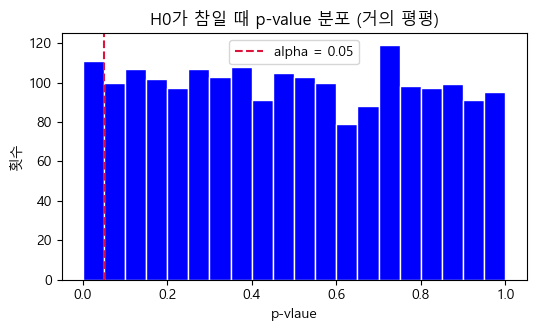

In [7]:
sim = np.random.default_rng(0)   # 시드 0으로 고정 → 실행할 때마다 같은 결과
TRIALS = 2000                    # 시뮬레이션 반복 횟수

def simulate_pvalues(true_diff, n, sd= 8):
    """
    평균 110인 집단 a와 평균 110+true_diff인 집단 b에서
    크기 n의 표본을 TRIALS번 뽑아 독립표본 t검정을 하고 p-value 배열을 반환
    """
    a = sim.normal(110, sd, (TRIALS, n))               # (2000, n) 모양: 한 행이 한 번의 실험
    b = sim.normal(110 + true_diff, sd, (TRIALS, n))
    return stats.ttest_ind(a, b, axis=1).pvalue        # axis=1 → 행마다 t검정 → p-value 2000개

# true_diff=0 → 두 집단 평균이 실제로 같음 (H0가 참인 상황)
p_h0 = simulate_pvalues(0, 30)

# 유의수준별로 '잘못 기각한 비율' 확인 → 각각 α 근처 값이 나와야 함
for a in [0.10, 0.05, 0.01] :
    print(f'alpah = {a:<4} -> 잘못 기각한 비율(1종 오류율) = {(p_h0 < a).mean() :.3f}')

# H0가 참일 때 p-value 분포 시각화
plt.figure(figsize= (6, 3.2))
plt.hist(p_h0, bins = 20, color= 'blue', edgecolor= 'white')
plt.axvline(0.05, color= 'crimson', ls= '--', label= 'alpha = 0.05')   # 이 선 왼쪽이 '잘못 기각'한 경우
plt.title('H0가 참일 때 p-value 분포 (거의 평평)')
plt.xlabel('p-vlaue')
plt.ylabel('횟수')
plt.legend()
plt.show()

## 4. 표본 크기와 검정력

이번에는 두 집단 평균이 **실제로 4만큼 다른** 상황(H0가 거짓)이다.
- **검정력(1-β)**: 실제 차이가 있을 때 그것을 제대로 잡아내는(기각하는) 확률
- **2종 오류(β)**: 실제 차이가 있는데 놓치는(기각하지 못하는) 확률
- 표본 크기 n이 커질수록 검정력이 올라간다. 관례적으로 **검정력 0.8 이상**을 목표로 한다.

 표본크기 n  검정력(1-Beta)  2종오류(B)
      5       0.1065   0.8935
     10       0.1855   0.8145
     20       0.3370   0.6630
     30       0.4810   0.5190
     50       0.7090   0.2910
    100       0.9470   0.0530


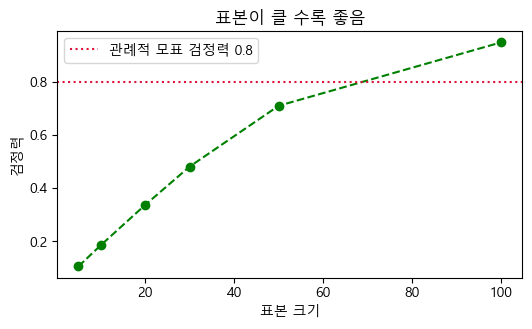

In [9]:
rows = []
for n in [5, 10, 20, 30, 50, 100]:
    p = simulate_pvalues(true_diff= 4, n= n)   # 실제 평균 차이 = 4
    power = (p < 0.05).mean()                   # 2000번 중 기각에 성공한 비율 = 검정력
    rows.append({'표본크기 n': n, '검정력(1-Beta)': power, '2종오류(B)' : 1 - power})

power_df = pd.DataFrame(rows)
print(power_df.to_string(index= False))

# 표본 크기에 따른 검정력 변화 그래프
plt.figure(figsize= (6, 3.2))
plt.plot(power_df['표본크기 n'], power_df['검정력(1-Beta)'], 'o--', color= 'green')
plt.axhline(0.8, color= 'crimson', ls= ':', label= '관례적 모표 검정력 0.8')   # 목표 기준선
plt.title('표본이 클 수록 좋음')
plt.xlabel('표본 크기')
plt.ylabel('검정력')
plt.legend()
plt.show()

## 5. α와 β의 트레이드오프

표본 크기(n=30)를 고정하고 유의수준 α만 바꿔 본다.
- α를 **낮추면**(엄격하게) 1종 오류는 줄지만, 기각이 어려워져 **검정력이 떨어지고 β가 커진다.**
- 즉 α와 β는 한쪽을 줄이면 다른 쪽이 커지는 관계 → 둘 다 줄이려면 표본을 늘려야 한다.

In [10]:
p = simulate_pvalues(true_diff= 4, n = 30)   # 실제 차이가 있는 상황, n=30 고정
for a in [0.10, 0.05, 0.01] :
    # 1종 오류 확률 = α (정의상)
    # 검정력       = p < α 인 비율
    # 2종 오류 β   = p >= α 인 비율 (= 1 - 검정력)
    print(f'alpha = {a:< 4} -> 1종오류 확률 = {a:<4} | 검정력 = {(p < a).mean():.3f} | 2종오류베타 = {(p >= a).mean():.3f}')

alpha =  0.1 -> 1종오류 확률 = 0.1  | 검정력 = 0.605 | 2종오류베타 = 0.395
alpha =  0.05 -> 1종오류 확률 = 0.05 | 검정력 = 0.477 | 2종오류베타 = 0.523
alpha =  0.01 -> 1종오류 확률 = 0.01 | 검정력 = 0.251 | 2종오류베타 = 0.749


## 6. 정규성 확인 (시각적 방법)

t검정, ANOVA 같은 모수 검정은 데이터가 **정규분포**를 따른다고 가정한다.
- **히스토그램**: 좌우 대칭인 종 모양인지 확인
- **Q-Q plot**: 점들이 대각선(직선) 위에 가깝게 놓이면 정규분포에 가까움

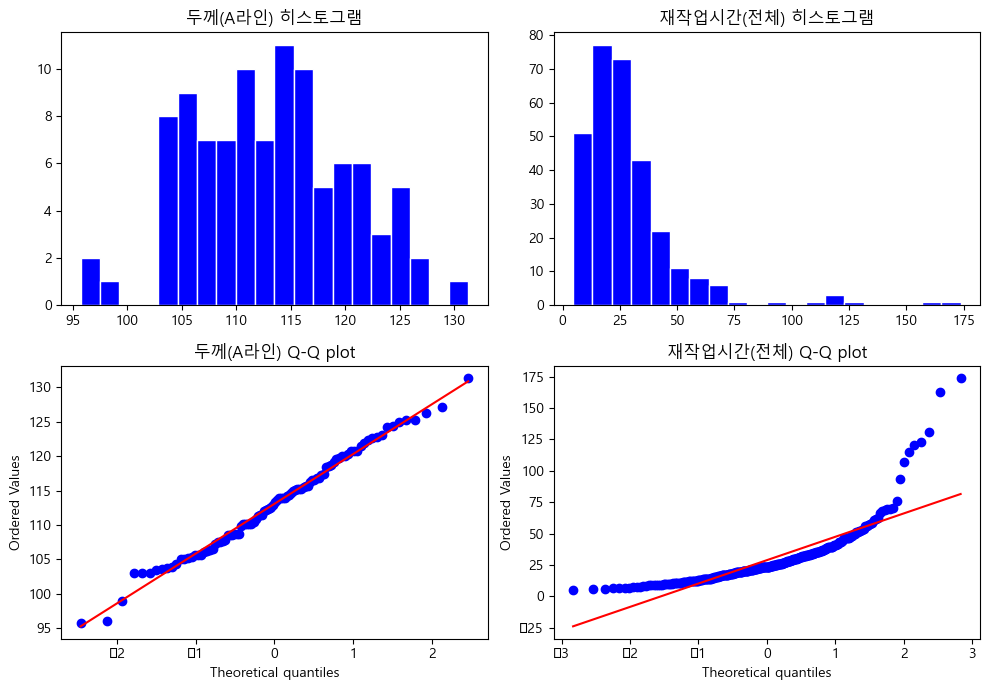

In [11]:
# 2행 2열 그래프: 윗줄은 히스토그램, 아랫줄은 Q-Q plot
fig, ax = plt.subplots(2, 2, figsize= (10, 7))
for col, (var, title) in enumerate([('thickness', '두께(A라인)'),
                                    ('rework_min', '재작업시간(전체)')]) :
    # thickness는 A라인 데이터만, rework_min은 전체 데이터 사용
    x = df.loc[df.line == 'A', var] if var == 'thickness' else df[var]
    ax[0, col].hist(x, bins = 20, color = 'blue', edgecolor = 'white')
    ax[0, col].set_title(f'{title} 히스토그램')
    # 정규분포 기준 Q-Q plot (직선에서 벗어날수록 정규성에서 멀어짐)
    stats.probplot(x, dist= 'norm', plot = ax[1, col])
    ax[1, col].set_title(f'{title} Q-Q plot')
plt.tight_layout()   # 그래프끼리 겹치지 않게 간격 자동 조정
plt.show()

## 7. 정규성 검정: Shapiro-Wilk

- **H0: 데이터는 정규분포를 따른다**
- p-value < 0.05 → H0 기각 → 정규분포가 아니다
- p-value ≥ 0.05 → H0 기각 못함 → 정규분포라고 봐도 무방
- 주의: 일반적인 검정과 달리 **기각되지 않아야** 정규성 가정을 만족한다고 본다.

In [12]:
# 연습용 작은 데이터(15개)로 먼저 Shapiro-Wilk 검정
l_data = np.array([119, 110, 108, 120, 117, 109, 96, 104, 123, 113, 129, 106, 93, 92, 102])

print(stats.shapiro(l_data))   # (statistic=W 통계량, pvalue)

# 라인별 두께와 재작업시간에 대해 정규성 검정을 반복 수행
for name, x in [('A라인 두께', df.loc[df.line == 'A', 'thickness']),
                ('B라인 두께', df.loc[df.line == 'B', 'thickness']),
                ('C라인 두께', df.loc[df.line == 'C', 'thickness']),
                ('재작업시간', df['rework_min'])]:
    res = stats.shapiro(x)
    # 위에서 만든 verdict()로 결과를 정해진 형식으로 출력
    verdict(f'정규성: {name}', res.pvalue, '데이터는 정규분포를 따른다',
            reject_msg= '정규분포가 아니다.', keep_msg= '정규분포라고 볼 수 있다.',
            stat = res.statistic)

ShapiroResult(statistic=0.9740516543388367, pvalue=0.9128594994544983)
-----[정규성: A라인 두께]-----
   H0: 데이터는 정규분포를 따른다     
검정통계량 = 0.9907
    p-value = 0.719597    >=    alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: B라인 두께]-----
   H0: 데이터는 정규분포를 따른다     
검정통계량 = 0.9891
    p-value = 0.594496    >=    alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: C라인 두께]-----
   H0: 데이터는 정규분포를 따른다     
검정통계량 = 0.9850
    p-value = 0.319109    >=    alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: 재작업시간]-----
   H0: 데이터는 정규분포를 따른다     
검정통계량 = 0.7161
    p-value = 0.000000    <    alpha = 0.05
귀무가설 기각 : 정규분포가 아니다.
